# Unsupervised Tasks: Bike Trip and Stations Profiles

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [4]:
import os
print(os.getcwd())

c:\Users\sorob\OneDrive\Desktop\DOCS IMPORTANT ECOLE\COURS IMT ATLANTIQUE FISE A2\SEMESTRE 7\COURS DASCI DATA SCIENCE\APPLIED STATISTICS\CHALLENGE FML\ML_Challenge\notebook


In [5]:
import os
import pandas as pd

DATA_DIR = r"C:\Users\sorob\OneDrive\Desktop\DOCS IMPORTANT ECOLE\COURS IMT ATLANTIQUE FISE A2\SEMESTRE 7\COURS DASCI DATA SCIENCE\APPLIED STATISTICS\CHALLENGE FML\bike_sharing_challenge_2026"

print(os.listdir(DATA_DIR))

['bikes.csv', 'bike_types.csv', 'cities.csv', 'stations.csv', 'stations_status.csv', 'trips_small.csv']


In [6]:
cities     = pd.read_csv(os.path.join(DATA_DIR, "cities.csv"))
bikes      = pd.read_csv(os.path.join(DATA_DIR, "bikes.csv"))
bike_types = pd.read_csv(os.path.join(DATA_DIR, "bike_types.csv"))
stations   = pd.read_csv(os.path.join(DATA_DIR, "stations.csv"))
status     = pd.read_csv(os.path.join(DATA_DIR, "stations_status.csv"))
trips      = pd.read_csv(os.path.join(DATA_DIR, "trips_small.csv"))

In [7]:
# Dimensions du fichier
print("Nombre de lignes et de colonnes :", cities.shape)

# Noms des colonnes
print("Colonnes :", cities.columns.tolist())

# Types des variables et valeurs non manquantes
cities.info()

# Afficher les premières lignes
display(cities.head())

# Afficher les dernières lignes
display(cities.tail())

Nombre de lignes et de colonnes : (267, 7)
Colonnes : ['id', 'name', 'lat', 'lon', 'timezone', 'country', 'return_to_official_only']
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 19.5 KB


,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


,id,name,lat,lon,timezone,country,return_to_official_only
262,853,Sant Just Desvern,41.3807,2.07496,Europe/Berlin,ES,True
263,856,Sant Boi de Llobregat,41.3458,2.03404,Europe/Berlin,ES,True
264,831,Wolsztyn,52.1120,16.10560,Europe/Warsaw,PL,True
265,143,Tulln,48.3269,16.05690,Europe/Berlin,AT,False
266,57,St.Pölten,48.2058,15.62320,Europe/Berlin,AT,True


In [8]:
# Nombre de valeurs manquantes par colonne
print(cities.isnull().sum())

# Pourcentage de valeurs manquantes
print((cities.isnull().mean() * 100).round(2))

# Nombre total de valeurs manquantes
print("Total :", cities.isnull().sum().sum())

id                         0
name                       0
lat                        0
lon                        0
timezone                   0
country                    0
return_to_official_only    0
dtype: int64
id                         0.0
name                       0.0
lat                        0.0
lon                        0.0
timezone                   0.0
country                    0.0
return_to_official_only    0.0
dtype: float64
Total : 0


In [9]:
# Nombre de lignes entièrement dupliquées
print("Lignes dupliquées :", cities.duplicated().sum())

# Vérifier l'unicité de l'identifiant
print("IDs dupliqués :", cities["id"].duplicated().sum())

# Vérifier les noms de villes dupliqués
print("Noms dupliqués :", cities["name"].duplicated().sum())

Lignes dupliquées : 0
IDs dupliqués : 0
Noms dupliqués : 0


In [16]:
cities[["lat", "lon"]].describe()

,lat,lon
count,267.000000,267.000000
mean,49.067596,12.154192
std,4.155125,7.029840
min,27.815400,-15.518200
25%,47.827850,8.306550
50%,49.898000,13.744600
75%,51.589750,16.831200
max,57.690200,33.453500


In [17]:
# Nombre de villes par pays
print(cities["country"].value_counts())

# Nombre de fuseaux horaires
print(cities["timezone"].nunique())

# Nombre de pays représentés
print(cities["country"].nunique())

# Répartition de la règle de retour des vélos
print(cities["return_to_official_only"].value_counts())

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64
9
15
return_to_official_only
True     200
False     67
Name: count, dtype: int64


In [ ]:
# Pays avec le plus de systèmes de vélos
country_counts = cities["country"].value_counts()

print(country_counts)

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64


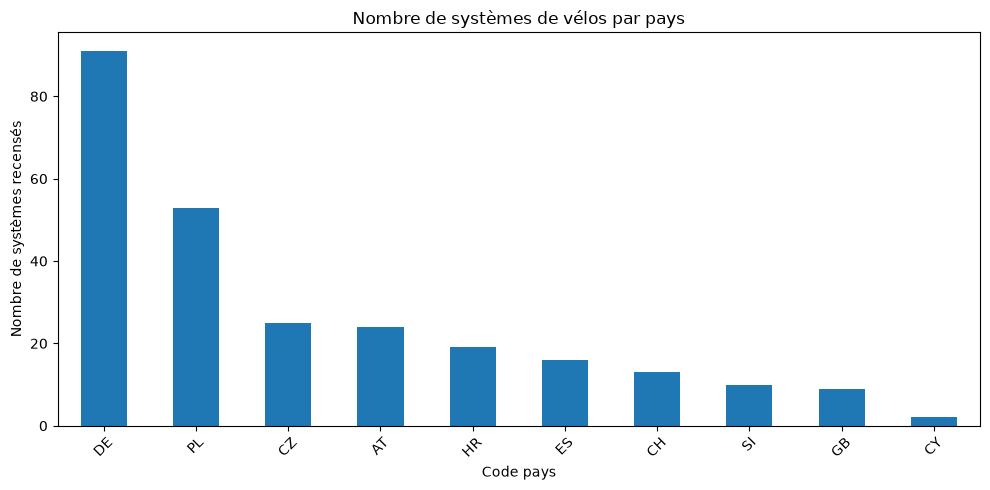

In [ ]:
# Visualisation
cities["country"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Nombre de systèmes de vélos par pays")
plt.xlabel("Code pays")
plt.ylabel("Nombre de systèmes recensés")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()